# 01 · PMData: understand the body data

**Questions**
1. What does one tidy daily table per person look like, and how much of it is missing?
2. How different are people from each other? (This is the argument for *personal* baselines.)
3. How does one person's signal behave over time: day-to-day memory, weekly rhythm, slow trends?
4. Do the body signals and the self-reports move together within a person?
5. What do injury days look like before and after?

**Inputs:** `data/raw/pmdata/` (real data: 16 people, Fitbit Versa 2 + PMSys self-reports).
**Outputs:** `data/processed/pmdata_daily.parquet`, `data/processed/pmdata_hourly_hr.parquet`, figures `reports/figures/01_*.png`, and a findings list.

In [1]:
import sys
sys.path.insert(0, "../ml")
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import acf
from sol_ml.nbutil import *
from sol_ml.data import pmdata

rng = setup()
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=RuntimeWarning)

## 1. Build the tables

In [2]:
daily = pmdata.build_all_daily()
daily.to_parquet(PROCESSED / "pmdata_daily.parquet", index=False)
print(daily.shape, "->", PROCESSED / "pmdata_daily.parquet")
daily.head()

(2398, 19) -> D:\AB.H\Downloads\sol-health\sol-health\data\processed\pmdata_daily.parquet


,person,date,resting_hr,sleep_minutes,deep_minutes,rem_minutes,sleep_score,restlessness,fatigue,mood,readiness,stress,soreness,sleep_quality,sleep_duration_h,steps,active_minutes,exercised,injury
0,p01,2019-11-01,53.741074,NaN,NaN,NaN,76.0,0.053635,2.0,3.0,5.0,3.0,2.0,3.0,6.0,17873.0,130.0,True,False
1,p01,2019-11-02,52.881497,378.0,36.0,83.0,79.0,0.078978,2.0,3.0,6.0,3.0,2.0,3.0,6.0,13118.0,99.0,True,False
2,p01,2019-11-03,53.222024,378.0,38.0,51.0,71.0,0.093491,3.0,3.0,8.0,3.0,3.0,3.0,6.0,14312.0,108.0,False,False
3,p01,2019-11-04,54.311141,361.0,37.0,35.0,68.0,0.064851,3.0,3.0,8.0,3.0,3.0,3.0,6.0,10970.0,51.0,True,False
4,p01,2019-11-05,52.259110,326.0,27.0,39.0,73.0,0.093185,3.0,3.0,8.0,3.0,3.0,3.0,5.0,16186.0,78.0,True,False


In [3]:
hourly = pd.concat([pmdata.load_hourly_hr(p).reset_index().assign(person=p.name) for p in pmdata.participants()],
                   ignore_index=True)[["person", "hour", "hr_mean", "hr_min", "hr_max", "n"]]
hourly.to_parquet(PROCESSED / "pmdata_hourly_hr.parquet", index=False)
print(hourly.shape, "hourly rows from", int(hourly.n.sum() / 1e6), "million raw heart-rate samples")
hourly.groupby("person").agg(hours=("hour", "count"), mean_bpm=("hr_mean", "mean")).round(1).T

(47672, 6) hourly rows from 20 million raw heart-rate samples


person,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p12,p13,p14,p15,p16
hours,3578.0,3417.0,1990.0,3404.0,3311.0,3606.0,3430.0,3216.0,3139.0,2510.0,2848.0,2053.0,1531.0,2774.0,3407.0,3458.0
mean_bpm,63.5,59.9,67.4,78.5,74.7,62.2,71.3,70.9,69.5,81.5,78.9,83.0,69.7,74.6,65.1,71.8


## 2. Missing data

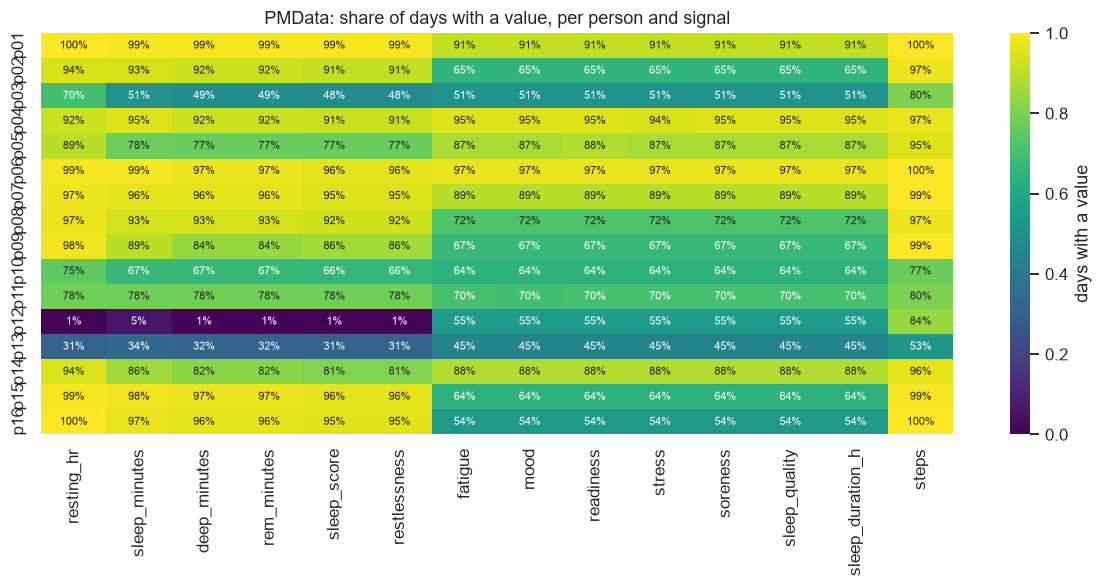

In [4]:
SIGNALS = ["resting_hr", "sleep_minutes", "deep_minutes", "rem_minutes", "sleep_score", "restlessness",
           "fatigue", "mood", "readiness", "stress", "soreness", "sleep_quality", "sleep_duration_h", "steps"]
present = daily.groupby("person")[SIGNALS].agg(lambda s: s.notna().mean())
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(present, annot=True, fmt=".0%", cmap="viridis", vmin=0, vmax=1, cbar_kws={"label": "days with a value"},
            annot_kws={"size": 7}, ax=ax)
ax.set(title="PMData: share of days with a value, per person and signal", xlabel="", ylabel="")
savefig("01_missing_heatmap");

In [5]:
def longest_gap(s):
    missing = s.isna().astype(int)
    return int(missing.groupby((missing == 0).cumsum()).sum().max())

gaps = daily.groupby("person").agg(
    days=("date", "count"),
    wellness_fill=("fatigue", lambda s: round(s.notna().mean(), 2)),
    wellness_longest_gap=("fatigue", longest_gap),
    resting_hr_fill=("resting_hr", lambda s: round(s.notna().mean(), 2)),
    resting_hr_longest_gap=("resting_hr", longest_gap),
    sleep_fill=("sleep_minutes", lambda s: round(s.notna().mean(), 2)),
    injury_days=("injury", "sum"))
print("overall fill: wellness %.0f%%, resting HR %.0f%%, sleep %.0f%%" % (
    100 * daily.fatigue.notna().mean(), 100 * daily.resting_hr.notna().mean(), 100 * daily.sleep_minutes.notna().mean()))
gaps

overall fill: wellness 72%, resting HR 82%, sleep 78%


,days,wellness_fill,wellness_longest_gap,resting_hr_fill,resting_hr_longest_gap,sleep_fill,injury_days
person,,,,,,,
p01,152,0.91,3,1.00,0,0.99,1
p02,152,0.65,3,0.94,6,0.93,1
p03,152,0.51,6,0.70,23,0.51,0
p04,152,0.95,1,0.92,6,0.95,3
p05,152,0.87,1,0.89,7,0.78,10
p06,152,0.97,1,0.99,1,0.99,0
p07,148,0.89,4,0.97,2,0.96,2
p08,143,0.72,7,0.97,3,0.93,0
p09,152,0.67,14,0.98,1,0.89,0


In [6]:
# People with enough data for the body models: at least 60 days of resting HR, sleep AND self-reports.
enough = gaps[(daily.groupby("person").resting_hr.count() >= 60) & (daily.groupby("person").sleep_minutes.count() >= 60)
              & (daily.groupby("person").fatigue.count() >= 60)].index.tolist()
print(len(enough), "usable people:", enough)
print("excluded:", sorted(set(gaps.index) - set(enough)))
core = daily[daily.person.isin(enough)]

14 usable people: ['p01', 'p02', 'p03', 'p04', 'p05', 'p06', 'p07', 'p08', 'p09', 'p10', 'p11', 'p14', 'p15', 'p16']
excluded: ['p12', 'p13']


## 3. How different are people from each other?

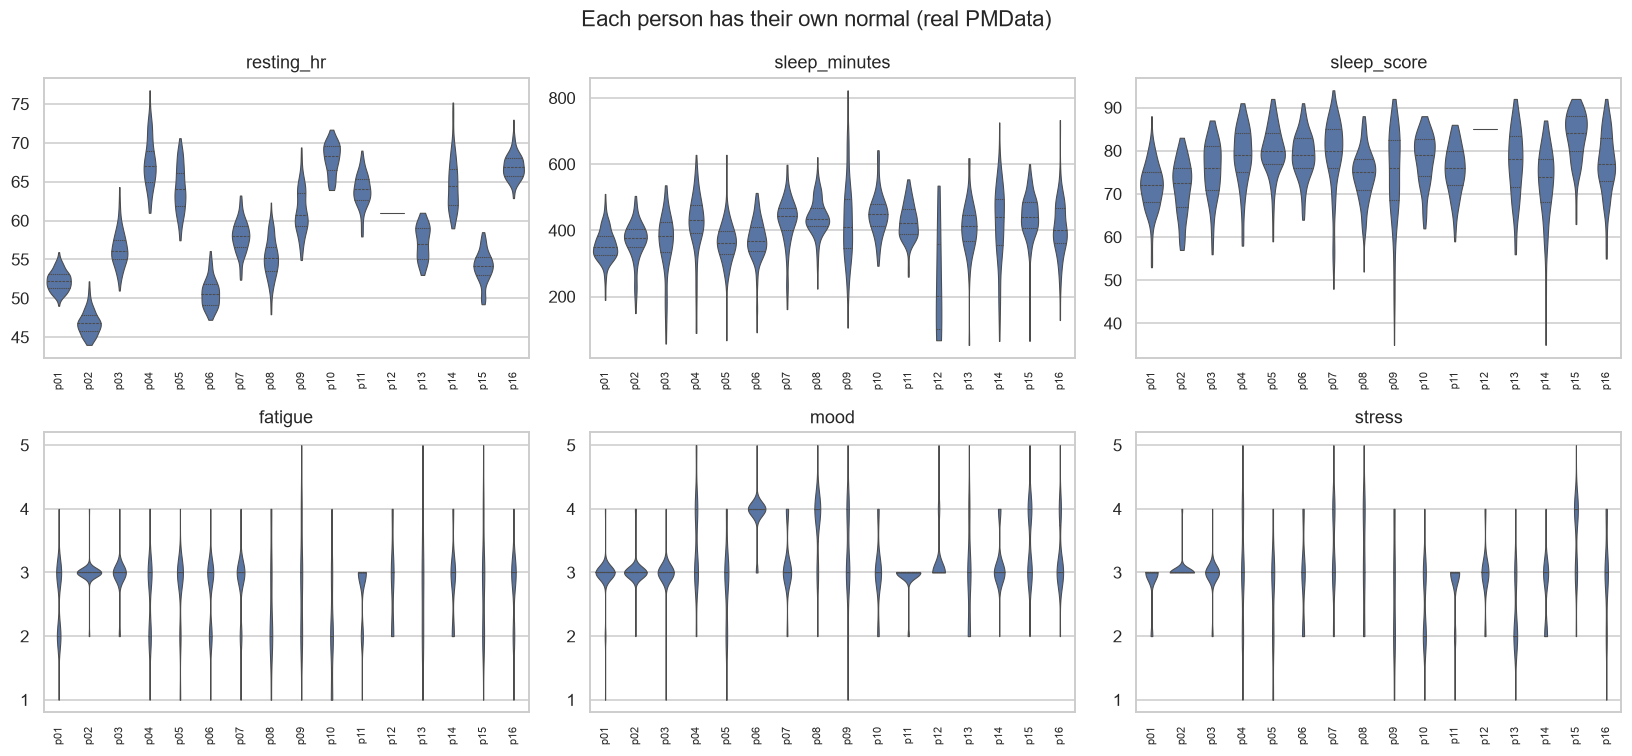

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), ["resting_hr", "sleep_minutes", "sleep_score", "fatigue", "mood", "stress"]):
    sns.violinplot(data=daily, x="person", y=col, ax=ax, inner="quartile", cut=0, linewidth=0.7, color="#4c72b0")
    ax.set(title=col, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=90, labelsize=7)
fig.suptitle("Each person has their own normal (real PMData)")
savefig("01_person_violins");

In [8]:
def robust_sd(s):
    s = s.dropna()
    return 1.4826 * np.median(np.abs(s - s.median())) if len(s) else np.nan

rows = []
for col in ["resting_hr", "sleep_minutes", "deep_minutes", "sleep_score", "fatigue", "mood", "stress", "readiness", "steps"]:
    g = core.groupby("person")[col]
    between, within = g.median().std(), g.std().median()
    rows.append({"signal": col, "between_person_sd": between, "median_within_person_sd": within,
                 "median_within_robust_sd": g.apply(robust_sd).median(),
                 "between/within": between / within,
                 "icc": between ** 2 / (between ** 2 + within ** 2)})
spread = pd.DataFrame(rows).set_index("signal").round(2)
spread

,between_person_sd,median_within_person_sd,median_within_robust_sd,between/within,icc
signal,,,,,
resting_hr,6.83,2.11,2.12,3.23,0.91
sleep_minutes,33.95,66.23,53.37,0.51,0.21
deep_minutes,15.57,21.43,19.64,0.73,0.35
sleep_score,3.28,6.22,5.93,0.53,0.22
fatigue,0.36,0.60,0.00,0.60,0.27
mood,0.36,0.53,0.00,0.69,0.32
stress,0.39,0.67,0.00,0.58,0.25
readiness,1.17,1.37,1.48,0.85,0.42
steps,4436.19,4376.76,4769.52,1.01,0.51


`between/within` above 1 means people differ from each other more than one person differs from day to day.
A population threshold on such a signal mostly measures *who* you are, not *how* you are today.

## 4. Within-person behaviour over time

,resting_hr,sleep_minutes,sleep_score,fatigue,mood,stress
lag 1,0.83,0.03,-0.01,0.12,0.13,0.25
lag 2,0.69,0.04,0.02,0.07,0.03,0.16
lag 3,0.57,0.08,0.04,0.03,0.00,0.13
lag 7,0.36,0.07,0.06,-0.00,0.01,0.09
lag 14,0.12,0.06,0.03,-0.01,0.03,0.03


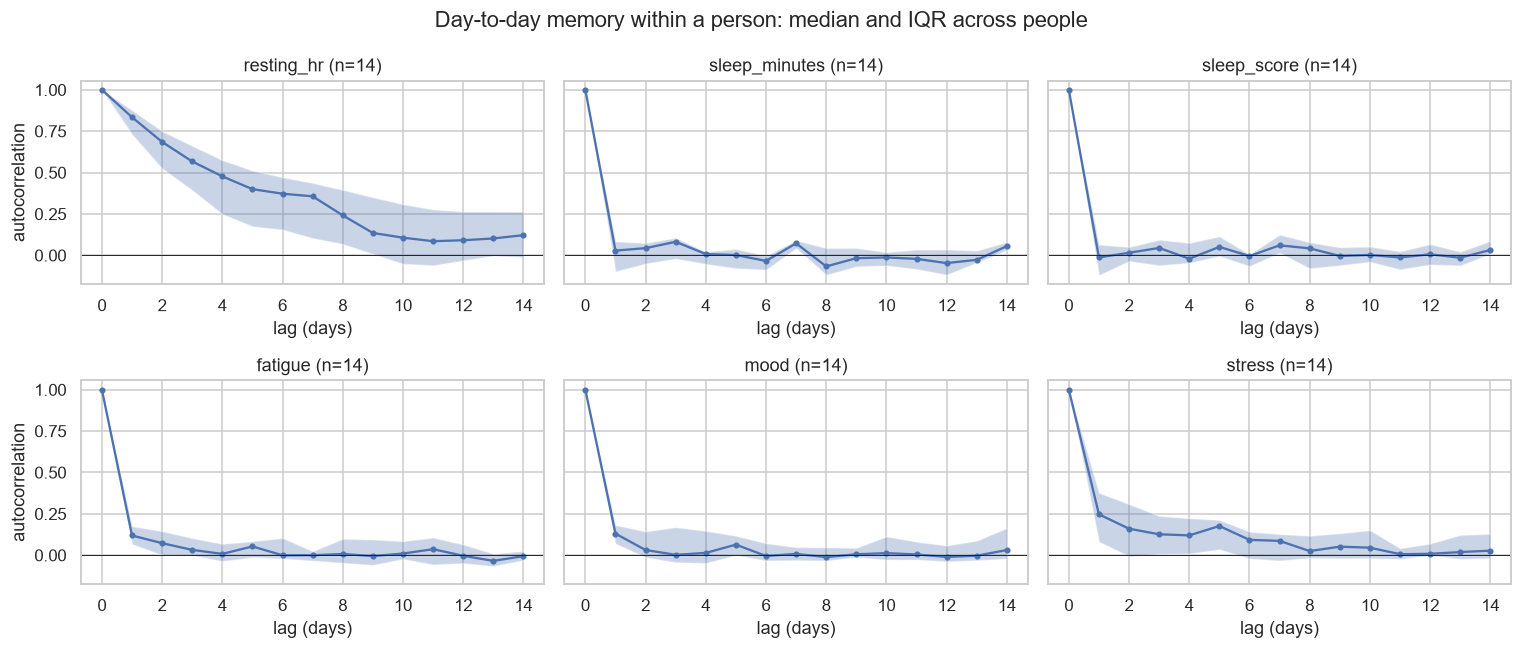

In [9]:
ACF_SIGNALS = ["resting_hr", "sleep_minutes", "sleep_score", "fatigue", "mood", "stress"]
LAGS = 14
acfs = {}
for col in ACF_SIGNALS:
    per = []
    for _, g in core.groupby("person"):
        s = g.set_index("date")[col]
        if s.notna().sum() >= 60 and s.std() > 0:
            per.append(acf(s, nlags=LAGS, missing="conservative"))
    acfs[col] = np.array(per)

fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)
for ax, col in zip(axes.ravel(), ACF_SIGNALS):
    a = acfs[col]
    ax.fill_between(range(LAGS + 1), np.nanpercentile(a, 25, axis=0), np.nanpercentile(a, 75, axis=0), alpha=0.3)
    ax.plot(np.nanmedian(a, axis=0), marker="o", ms=3)
    ax.axhline(0, color="k", lw=0.6)
    ax.set(title=f"{col} (n={len(a)})", xlabel="lag (days)")
axes[0, 0].set_ylabel("autocorrelation"); axes[1, 0].set_ylabel("autocorrelation")
fig.suptitle("Day-to-day memory within a person: median and IQR across people")
savefig("01_acf");
pd.DataFrame({c: np.nanmedian(a, axis=0)[[1, 2, 3, 7, 14]] for c, a in acfs.items()}, index=["lag 1", "lag 2", "lag 3", "lag 7", "lag 14"]).round(2)

In [10]:
# Weekly rhythm: weekend minus weekday mean, in units of the person's own SD.
core = core.assign(weekend=core.date.dt.day_of_week >= 5, dow=core.date.dt.day_of_week)
rows = []
for col in ["resting_hr", "sleep_minutes", "sleep_score", "fatigue", "mood", "stress", "steps", "active_minutes"]:
    d = []
    for _, g in core.groupby("person"):
        if g[col].std() > 0:
            d.append((g.loc[g.weekend, col].mean() - g.loc[~g.weekend, col].mean()) / g[col].std())
    d = np.array(d)
    rows.append({"signal": col, "median_effect_sd": np.median(d), "people_higher_on_weekend": int((d > 0).sum()),
                 "n": len(d), "wilcoxon_p": stats.wilcoxon(d).pvalue})
weekly = pd.DataFrame(rows).set_index("signal").round(3)
weekly

,median_effect_sd,people_higher_on_weekend,n,wilcoxon_p
signal,,,,
resting_hr,0.227,12,14,0.002
sleep_minutes,0.321,10,14,0.104
sleep_score,0.038,9,14,0.808
fatigue,0.069,10,14,0.241
mood,0.142,9,14,0.194
stress,0.216,11,14,0.007
steps,-0.108,6,14,0.391
active_minutes,0.024,7,14,1.000


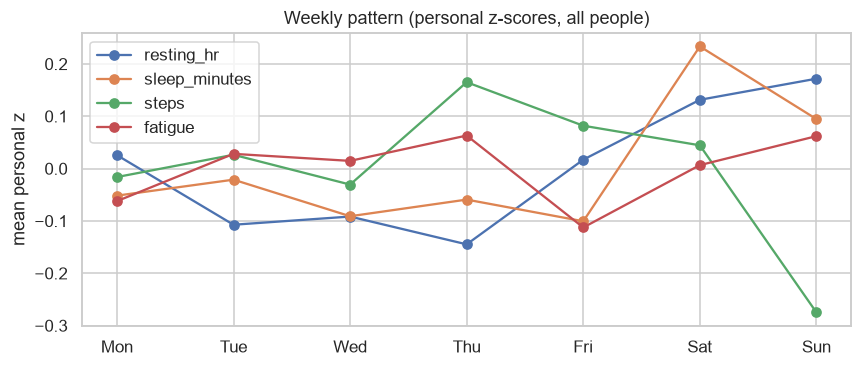

In [11]:
z = core.copy()
for col in ["resting_hr", "sleep_minutes", "steps", "fatigue"]:
    z[col] = z.groupby("person")[col].transform(lambda s: (s - s.mean()) / s.std())
fig, ax = plt.subplots(figsize=(8, 3.5))
z.groupby("dow")[["resting_hr", "sleep_minutes", "steps", "fatigue"]].mean().plot(marker="o", ax=ax)
ax.set(xticks=range(7), xticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], xlabel="",
       ylabel="mean personal z", title="Weekly pattern (personal z-scores, all people)")
savefig("01_weekly_pattern");

                min   25%   50%   75%   max
signal                                     
fatigue       -0.00 -0.00  0.00 -0.00 -0.00
resting_hr    -0.64 -0.16  0.00  0.16  0.34
sleep_minutes -0.10 -0.04  0.03  0.07  0.12


person,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p14,p15,p16
signal,resting_hr,resting_hr,resting_hr,resting_hr,resting_hr,resting_hr,resting_hr,resting_hr,resting_hr,resting_hr,resting_hr,resting_hr,resting_hr,resting_hr
per_30d,-0.21,0.34,-0.98,1.02,0.42,0.32,0.58,0.18,-0.3,-0.34,-0.15,-1.47,-1.08,0.18
per_30d_in_sd,-0.16,0.23,-0.46,0.34,0.13,0.17,0.27,0.07,-0.09,-0.16,-0.07,-0.41,-0.64,0.11
total_change,-1.07,1.66,-4.93,4.94,2.13,1.6,2.8,0.83,-1.49,-1.26,-0.58,-6.77,-5.15,0.92


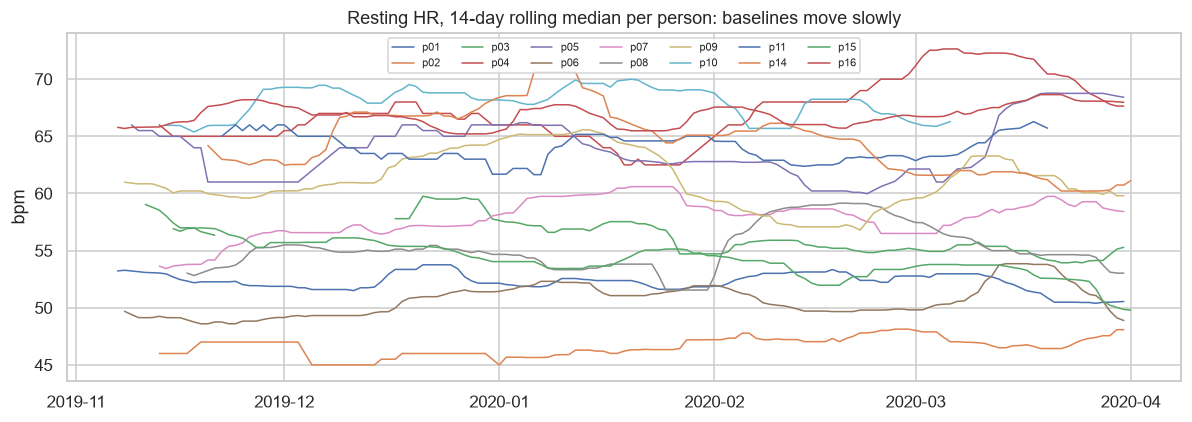

In [12]:
# Slow trends: Theil-Sen slope of each person's whole record, expressed per 30 days in the person's robust SD.
rows = []
for person, g in core.groupby("person"):
    for col in ["resting_hr", "sleep_minutes", "fatigue"]:
        s = g.set_index("date")[col].dropna()
        days = (s.index - s.index[0]).days.values
        slope = stats.theilslopes(s.values, days)[0]
        rows.append({"person": person, "signal": col, "per_30d": slope * 30, "per_30d_in_sd": slope * 30 / robust_sd(s) if robust_sd(s) else np.nan,
                     "total_change": slope * days[-1]})
trend = pd.DataFrame(rows)
print(trend.groupby("signal").per_30d_in_sd.describe()[["min", "25%", "50%", "75%", "max"]].round(2))
fig, ax = plt.subplots(figsize=(11, 4))
for person, g in core.groupby("person"):
    s = g.set_index("date").resting_hr
    ax.plot(s.rolling(14, min_periods=7).median(), lw=1, label=person)
ax.set(title="Resting HR, 14-day rolling median per person: baselines move slowly", ylabel="bpm", xlabel="")
ax.legend(ncol=7, fontsize=7, loc="upper center")
savefig("01_resting_hr_trends");
trend[trend.signal == "resting_hr"].set_index("person").round(2).T

## 5. Do body signals and self-reports move together within a person?

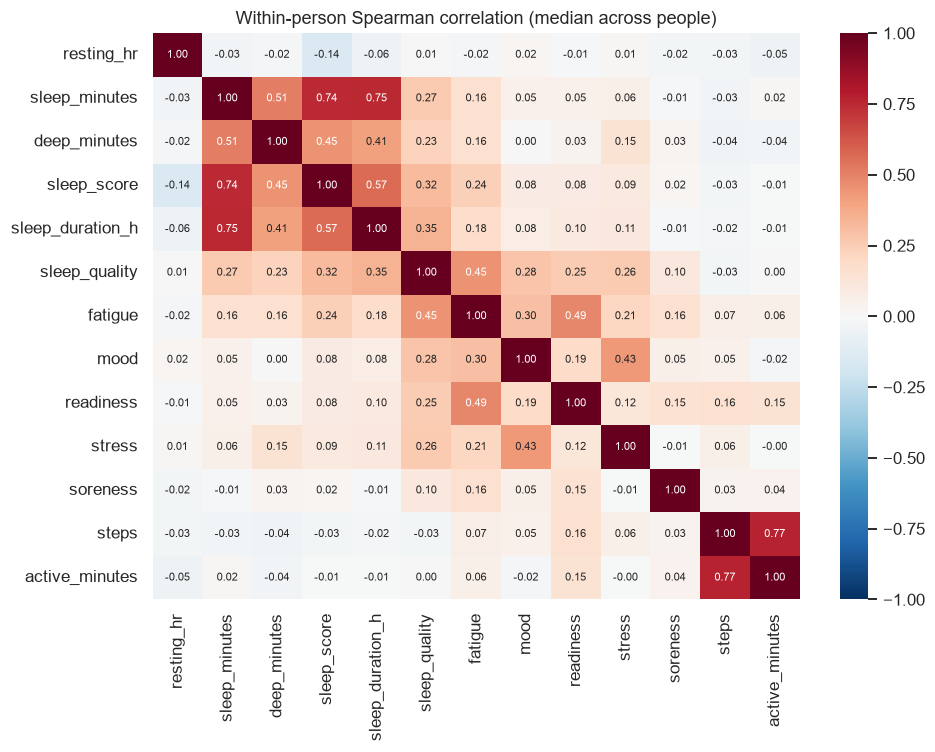

In [13]:
CORR = ["resting_hr", "sleep_minutes", "deep_minutes", "sleep_score", "sleep_duration_h", "sleep_quality",
        "fatigue", "mood", "readiness", "stress", "soreness", "steps", "active_minutes"]
mats = np.array([g[CORR].corr(method="spearman").values for _, g in core.groupby("person")])
med = pd.DataFrame(np.nanmedian(mats, axis=0), index=CORR, columns=CORR)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(med, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Within-person Spearman correlation (median across people)")
savefig("01_within_person_corr");

In [14]:
PAIRS = [("resting_hr", "fatigue"), ("resting_hr", "sleep_minutes"), ("sleep_minutes", "mood"), ("sleep_minutes", "fatigue"),
         ("sleep_duration_h", "sleep_minutes"), ("sleep_quality", "sleep_score"), ("mood", "stress"), ("fatigue", "readiness"),
         ("fatigue", "soreness"), ("mood", "fatigue")]
rows = []
for a, b in PAIRS:
    r = np.array([g[[a, b]].corr(method="spearman").iloc[0, 1] for _, g in core.groupby("person")])
    r = r[~np.isnan(r)]
    rows.append({"pair": f"{a} ~ {b}", "median_r": np.median(r), "min_r": r.min(), "max_r": r.max(),
                 "people_same_sign": int((np.sign(r) == np.sign(np.median(r))).sum()), "n": len(r)})
pairs = pd.DataFrame(rows).set_index("pair").round(2)
pairs

,median_r,min_r,max_r,people_same_sign,n
pair,,,,,
resting_hr ~ fatigue,-0.02,-0.22,0.17,8,14
resting_hr ~ sleep_minutes,-0.03,-0.17,0.15,7,14
sleep_minutes ~ mood,0.05,-0.11,0.27,11,14
sleep_minutes ~ fatigue,0.16,-0.20,0.55,10,14
sleep_duration_h ~ sleep_minutes,0.75,0.20,0.96,14,14
sleep_quality ~ sleep_score,0.32,-0.02,0.54,13,14
mood ~ stress,0.43,0.02,0.77,14,14
fatigue ~ readiness,0.49,0.18,0.71,14,14
fatigue ~ soreness,0.16,-0.11,0.62,11,14


In [15]:
# Same-day vs next-day: does last night's sleep relate to today's report, and does today's report lead tomorrow's resting HR?
rows = []
for person, g in core.groupby("person"):
    g = g.set_index("date")
    rows.append({"person": person,
                 "fatigue_today ~ resting_hr_tomorrow": g.fatigue.corr(g.resting_hr.shift(-1), method="spearman"),
                 "resting_hr_today ~ fatigue_tomorrow": g.resting_hr.corr(g.fatigue.shift(-1), method="spearman"),
                 "sleep_minutes ~ fatigue_same_day": g.sleep_minutes.corr(g.fatigue, method="spearman")})
pd.DataFrame(rows).set_index("person").median().round(2)

fatigue_today ~ resting_hr_tomorrow   -0.03
resting_hr_today ~ fatigue_tomorrow    0.06
sleep_minutes ~ fatigue_same_day       0.16
dtype: float64

## 6. Injury days: what happens before and after?

{'p01': 1, 'p02': 1, 'p04': 3, 'p05': 10, 'p07': 2, 'p11': 2, 'p12': 44, 'p14': 3, 'p15': 6}
22 injury onsets in 9 people


,resting_hr,sleep_minutes,fatigue,soreness,readiness,mood,steps
-7,-0.19,-0.22,0.20,0.50,0.14,0.42,-0.25
-3,-0.06,0.06,-0.34,-0.23,-0.24,-0.08,-0.03
-1,0.25,-0.21,-0.78,-0.17,-0.47,0.52,-0.23
0,0.14,-0.78,-0.22,-0.55,-0.35,-0.29,0.35
1,-0.16,0.03,-0.39,-0.71,-0.21,0.23,-0.30
3,-0.39,-0.13,-0.21,-0.13,-0.52,0.57,0.24
7,0.19,-0.71,-0.26,-0.25,0.15,-0.06,0.20
n at day 0,14.00,14.00,21.00,21.00,21.00,21.00,20.00


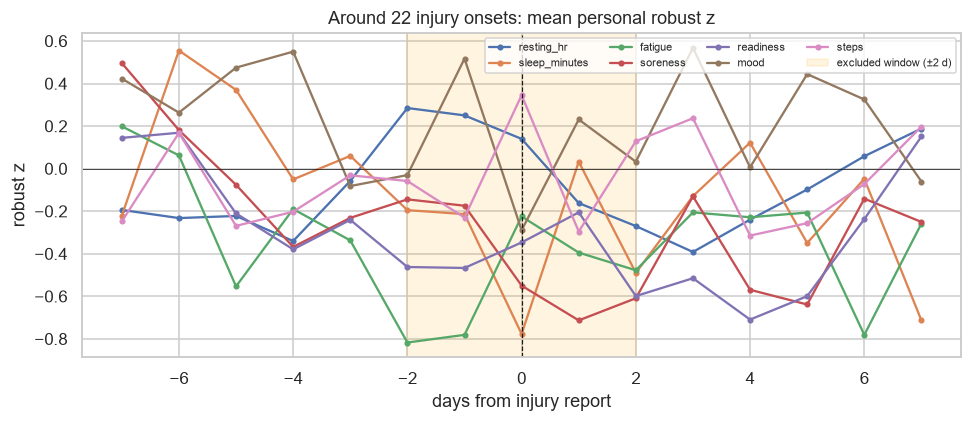

In [16]:
inj = daily[daily.injury]
print(inj.groupby("person").size().to_dict())
# an injury *episode* starts on an injury day with no injury report in the 7 days before it
onsets = []
for person, g in daily.groupby("person"):
    days = g.loc[g.injury, "date"].sort_values()
    onsets += [(person, d) for d, prev in zip(days, days.shift()) if pd.isna(prev) or (d - prev).days > 7]
print(len(onsets), "injury onsets in", len({p for p, _ in onsets}), "people")

EV = ["resting_hr", "sleep_minutes", "fatigue", "soreness", "readiness", "mood", "steps"]
zed = daily.copy()
for col in EV:
    zed[col] = zed.groupby("person")[col].transform(lambda s: (s - s.median()) / (robust_sd(s) or s.std() or np.nan))
frames = []
for person, d0 in onsets:
    g = zed[zed.person == person].set_index("date")[EV]
    w = g.reindex(pd.date_range(d0 - pd.Timedelta(days=7), d0 + pd.Timedelta(days=7)))
    w.index = range(-7, 8)
    frames.append(w)
event = pd.concat(frames).groupby(level=0)
fig, ax = plt.subplots(figsize=(9, 4))
event.mean().plot(marker="o", ms=3, ax=ax)
ax.axvline(0, color="k", ls="--", lw=0.8); ax.axhline(0, color="k", lw=0.5)
ax.axvspan(-2, 2, color="orange", alpha=0.12, label="excluded window (±2 d)")
ax.set(title=f"Around {len(onsets)} injury onsets: mean personal robust z", xlabel="days from injury report", ylabel="robust z")
ax.legend(ncol=4, fontsize=7)
savefig("01_injury_event_study");
pd.concat([event.mean().loc[[-7, -3, -1, 0, 1, 3, 7]].round(2), event.count().loc[[0]].rename({0: "n at day 0"})])

## 7. Heart rate through the day (for the crew generator)

night trough 59 bpm at 04:00, day peak 80 bpm at 14:00


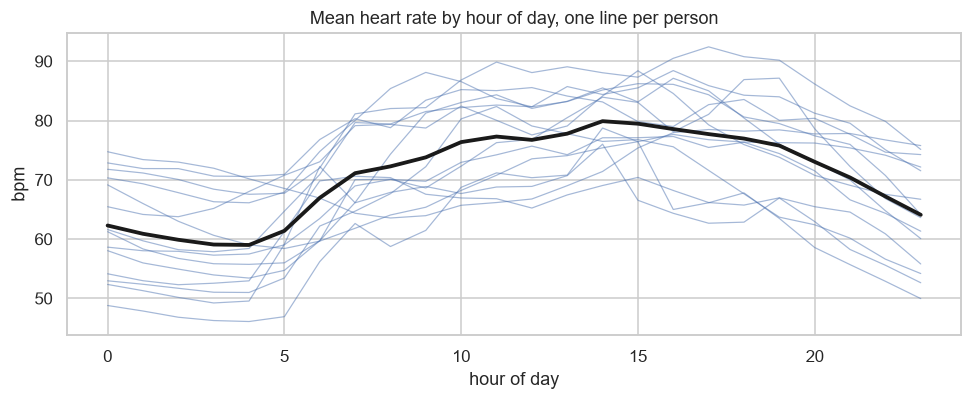

In [17]:
hourly["hod"] = hourly.hour.dt.hour
prof = hourly[hourly.person.isin(enough)].groupby(["person", "hod"]).hr_mean.mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 3.8))
prof.plot(ax=ax, lw=0.8, legend=False, color="#4c72b0", alpha=0.5)
prof.mean(axis=1).plot(ax=ax, lw=2.5, color="k", label="mean of people")
ax.set(title="Mean heart rate by hour of day, one line per person", xlabel="hour of day", ylabel="bpm")
savefig("01_hr_diurnal");
print("night trough %.0f bpm at %02d:00, day peak %.0f bpm at %02d:00" % (
    prof.mean(axis=1).min(), prof.mean(axis=1).idxmin(), prof.mean(axis=1).max(), prof.mean(axis=1).idxmax()))

## Findings

1. **14 of 16 people are usable.** p12 (one night of Fitbit data, 44 injury days) and p13 (31 % resting-HR coverage) are excluded from the body models.
   Across everyone, wellness is filled in on 72 % of days, resting HR on 82 % and sleep on 78 %. Gaps of 1–2 weeks are common
   (p10 has a 31-day gap), so **every detector must tolerate missing days** rather than assume a daily series.
2. **Resting HR is a personal constant; a population threshold would be wrong.** People differ by 6.8 bpm (SD of personal medians),
   while one person varies by only 2.1 bpm day to day: 91 % of resting-HR variance is *between* people.
   Sleep, mood, fatigue and stress are the opposite (20–30 % between people), so for them a personal baseline helps less.
3. **Resting HR has a long memory; the other signals have almost none.** Lag-1 autocorrelation is 0.83 for resting HR (still 0.36 after a week),
   but 0.03 for sleep minutes and 0.12–0.25 for the self-reports. Consequences: resting-HR z-scores on consecutive days are *not* independent
   (CUSUM/EWMA limits tuned for independent data will fire too often), and the crew generator needs an AR(1) resting HR with φ ≈ 0.8 and near-white sleep.
4. **Baselines drift without anything being wrong.** Over 5 months the personal resting-HR trend ranged from −6.8 to +4.9 bpm (up to 0.6 robust SD per 30 days).
   A fixed baseline from the first weeks would raise false alarms; a rolling window is required.
5. **Weekly rhythm is small but real for resting HR**: +0.23 personal SD at weekends (12 of 14 people, p = 0.002). Sleep is longer at weekends (+0.32 SD, not significant).
6. **Body signals and self-reports barely move together within a person.** Resting HR vs fatigue: median r = −0.02. Sleep minutes vs mood: 0.05.
   The self-reports do agree with each other (mood ~ stress 0.43, fatigue ~ readiness 0.49), and reported sleep hours track Fitbit sleep (0.75).
   So the multi-signal cases in the plan (resting HR ↑ *and* fatigue ↑ together) do not occur naturally in this data, which is good for specificity
   but means their detection can only be tested with planted changes.
7. **Injury onsets (22 in 9 people) leave a weak, noisy footprint**: the day before a report fatigue is 0.8 robust SD worse and sleep is 0.8 SD shorter on the day,
   while resting HR barely moves (+0.1 to +0.25 SD). With n = 14–21 per day this is suggestive only. The ±2-day exclusion window in the protocol is reasonable.
8. Heart rate through the day: night trough 59 bpm at 04:00, day peak 80 bpm at 14:00 (mean of people). This shapes the hourly generator.

## Decision

**Chosen:** the daily table (`pmdata_daily.parquet`: person, date, 17 columns) and hourly HR table are the inputs to notebooks 02, 03 and 08.
Body models run on the **14 usable people**. Resting HR uses Fitbit's daily estimate, filled from the nightly sleep-score value when the daily one is missing
(this raised p02 from at most 91 to 143 days and p04 from at most 35 to 140).

**Two things do not fit the plan as written (also reported in chat):**
- **The self-report scales run the other way.** In PMSys a *higher* fatigue, stress, soreness or mood score is *better* (fatigue correlates +0.49 with readiness and +0.30 with mood;
  this is inferred from the data and matches the PMSys convention of 3 = normal, 5 = best). The plan's "fatigue ↑, stress ↑" therefore means these *scores go down*.
  Notebook 02 flips them into "badness" so that a positive z always means worse.
- **The robust z-score in the plan is undefined for the self-reports.** They are 1–5 integers that sit on one value most days, so their MAD is 0 for the typical person
  (median within-person robust SD = 0.00 for fatigue, mood and stress) and `z = (x − median) / (1.4826·MAD)` divides by zero. Injections "scaled to the robust SD" hit the same problem.
  Notebook 02 needs a fallback scale for these signals (proposed: the mean absolute deviation with a floor of half a scale point) and must say so.

**Rejected:** using all 16 people (p12 and p13 would contribute almost no heart data); dropping days with any missing value (it would remove about 40 % of days).

**Known limits:** healthy athletes, winter 2019–20, no medical events. Self-reports are coarse (5 levels). 0 on a 1–5 scale was treated as "not answered".